In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical

In [6]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("saurabh00007/iriscsv")
df = pd.read_csv(os.path.join(path,"Iris.csv"))


100%|██████████| 1.28k/1.28k [00:00<00:00, 2.21MB/s]

Extracting files...


In [7]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
df['Species'].value_counts()

,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [10]:
X = df.drop(columns=['Species','Id'])
y = df['Species']

In [11]:
df.shape

(150, 6)

In [12]:
encoder = LabelEncoder()
y_label = encoder.fit_transform(y)

In [13]:
y_label

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y_label,
 test_size=0.33, random_state=42,stratify=y_label)

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [16]:
per = Perceptron(max_iter=1000, random_state=42)
per.fit(X_train_scaled,y_train)

Perceptron(random_state=42)

In [17]:
y_pred = per.predict(X_test_scaled)

In [18]:
accuracy_score(y_test,y_pred)

0.76

In [19]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.79      0.94      0.86        16
           1       0.78      0.41      0.54        17
           2       0.73      0.94      0.82        17

    accuracy                           0.76        50
   macro avg       0.76      0.76      0.74        50
weighted avg       0.76      0.76      0.74        50



In [23]:
y_train_cat = to_categorical(y_train,num_classes=3)
y_test_cat = to_categorical(y_test,num_classes=3)

In [24]:
model = Sequential([
    Dense(16,input_dim=4,activation='relu'),
    Dense(8,activation='relu'),
    Dense(3,activation='softmax')
])

In [27]:
model.compile(optimizer='adam',
loss='categorical_crossentropy',metrics=['accuracy'])

In [28]:
history = model.fit(X_train_scaled,y_train_cat,
epochs=100,batch_size=8,validation_split=0.2,verbose = 1)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.1250 - loss: 1.2254 - val_accuracy: 0.3500 - val_loss: 1.1338
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1500 - loss: 1.1581 - val_accuracy: 0.4000 - val_loss: 1.0794
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1750 - loss: 1.0948 - val_accuracy: 0.3500 - val_loss: 1.0373
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2375 - loss: 1.0392 - val_accuracy: 0.5000 - val_loss: 0.9952
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4000 - loss: 0.9906 - val_accuracy: 0.6000 - val_loss: 0.9523
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5750 - loss: 0.9448 - val_accuracy: 0.7000 - val_loss: 0.9106
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7125 - loss: 0.9047 - val_accuracy: 0.8000 - val_loss: 0.8683
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8375 - loss: 0.8635 - val_accuracy: 0.8

In [29]:
acc = model.evaluate(X_test_scaled,y_test_cat,verbose=1)
print(acc)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.9000 - loss: 0.1845
[0.18453344702720642, 0.8999999761581421]


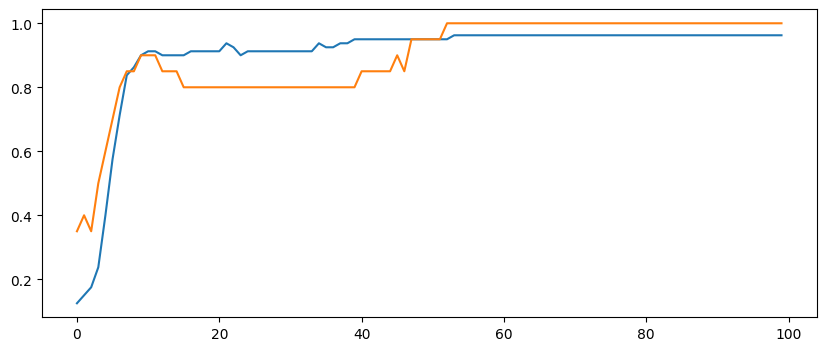

In [31]:
plt.figure(figsize = (10,4))
plt.plot(history.history['accuracy'],label="train Acc")
plt.plot(history.history['val_accuracy'],label="val Acc")